# DSCI 552 — Homework 4: Time Series Classification

Binary and multiclass classification of human activities from wireless sensor time series (UCI **AReM** dataset), using time-domain features extracted from each series.

**Contents:** feature extraction for any number of segments *l* · logistic regression with recursive feature elimination and 5-fold cross-validation over (*l*, *p*) · case-control sampling · L1-penalized logistic regression · L1 multinomial regression and Naive Bayes for 7 activities · ISLR 4.8.3 and 4.8.7.

## Setup

In [1]:
import os
from pathlib import Path
os.chdir(Path.home() / "Documents" / "DSCI552" / "HW3")

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay, accuracy_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB

sns.set_theme(style="whitegrid")

## 1. Data loading and feature extraction (from Homework 3)

The AReM data is not included in this repository. Download it from the [UCI repository](https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29) and unzip it so that the activity folders are at `AReM/AReM/` next to this notebook.

**Train/test split (1b):** datasets 1–2 in `bending1` and `bending2`, and datasets 1–3 in every other folder, are test data (19 instances); the rest are training data (69 instances).

**Data cleaning notes:**
- `bending2/dataset4.csv` separates values with spaces instead of commas, so all files are read with a regex separator that accepts both.
- `cycling/dataset14.csv` has an extra field on its last line; `usecols=range(7)` keeps only the time column and the 6 series.
- `sitting/dataset8.csv` is missing one reading (time 13500); it is kept as-is, since one value out of 480 has a negligible effect on the features.

In [3]:
candidates = [Path("AReM") / "AReM", Path("HW3") / "AReM" / "AReM"]
data_dir = next((p for p in candidates if p.exists()), candidates[0])

raw = []
for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        for file in sorted(folder.glob("*.csv")):
            num = int(file.stem.removeprefix("dataset"))
            if folder.name.startswith("bending"):
                split = "test" if num <= 2 else "train"
            else:
                split = "test" if num <= 3 else "train"

            df = pd.read_csv(file, skiprows=5, header=None, sep=r"[,\s]+",
                             engine="python", usecols=range(7))
            raw.append({"activity": folder.name, "dataset": num,
                        "split": split, "data": df.iloc[:, 1:7]})

print(len(raw))

88


Check that no file has missing values after loading (this prints nothing if the data is clean):

In [4]:
for inst in raw:
    n = inst["data"].isna().sum().sum()
    if n > 0:
        print(inst["activity"], inst["dataset"], "missing values:", n)

**Feature function.** Each of the 6 series is split into *l* approximately equal pieces, and the 7 time-domain features (min, max, mean, median, standard deviation, first and third quartiles) are computed for each piece. Feature groups are numbered consecutively, so for *l* = 2, groups 1–2 are the halves of series 1, groups 3–4 the halves of series 2, and so on.

In [5]:
def make_features(raw, l):
    rows = []
    for inst in raw:
        row = {"activity": inst["activity"], "dataset": inst["dataset"],
               "split": inst["split"]}
        k = 1
        for col in inst["data"].columns:
            pieces = [pd.Series(p) for p in np.array_split(inst["data"][col].to_numpy(), l)]
            for s in pieces:
                row[f"min{k}"] = s.min()
                row[f"max{k}"] = s.max()
                row[f"mean{k}"] = s.mean()
                row[f"median{k}"] = s.median()
                row[f"std{k}"] = s.std()
                row[f"1st_quart{k}"] = s.quantile(0.25)
                row[f"3rd_quart{k}"] = s.quantile(0.75)
                k += 1
        rows.append(row)
    return pd.DataFrame(rows)

In [6]:
print(make_features(raw, 1).shape)
print(make_features(raw, 2).shape)

(88, 45)
(88, 87)


## 2. Time Series Classification Part 2

### 2(a)i Scatter plots: bending vs. other activities

Features selected in 1(c)iv (min, mean, max) from series 1, 2, and 6, training set only.

['min1', 'mean1', 'max1', 'min2', 'mean2', 'max2', 'min6', 'mean6', 'max6']


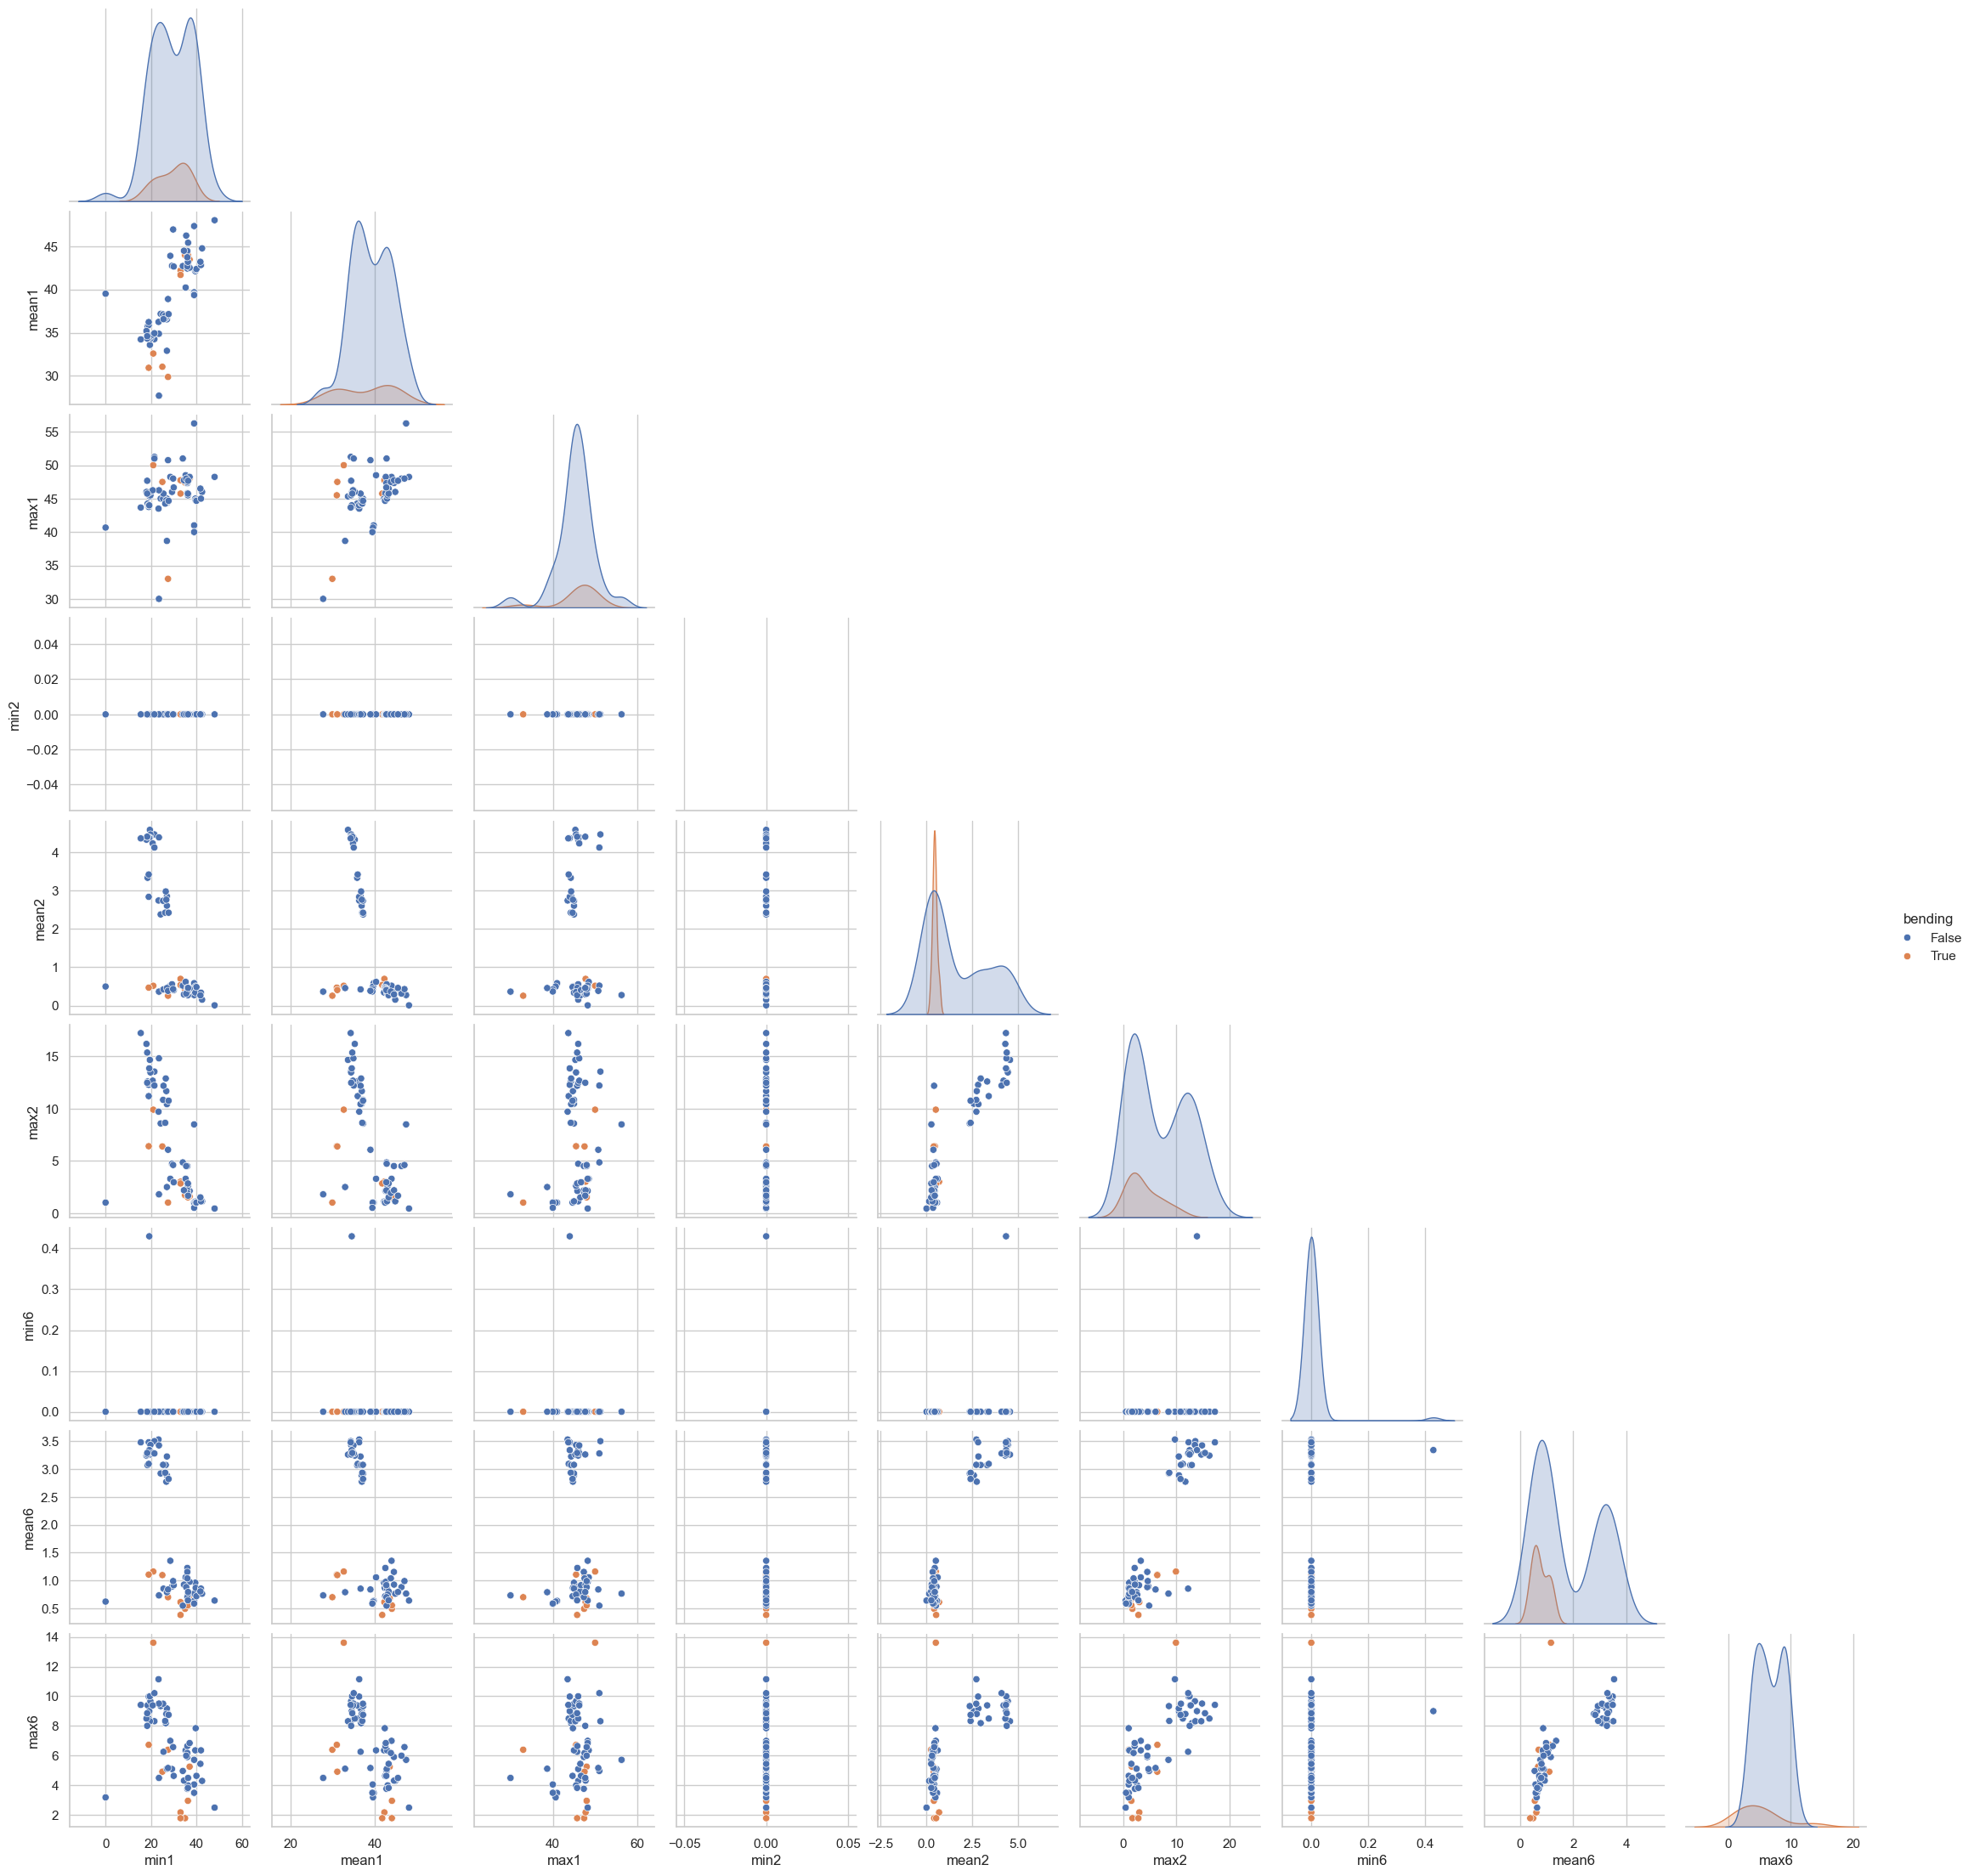

In [7]:
f1 = make_features(raw, 1)
train1 = f1[f1["split"] == "train"].copy()
train1["bending"] = train1["activity"].str.startswith("bending")

cols = [f"{stat}{k}" for k in [1, 2, 6] for stat in ["min", "mean", "max"]]
print(cols)

sns.pairplot(train1, vars=cols, hue="bending", corner=True)
plt.show()

No single pair of features cleanly separates bending from the other activities. In the series 2 and 6 features, the instances split into a low-variance cluster (non-moving activities) and a high-variance cluster (cycling, walking); the bending instances fall inside the low-variance cluster together with lying, sitting, and standing. The series 1 features (`min1`, `mean1`) separate bending partially but still overlap with other activities. `min2` and `min6` are essentially constant at 0 and carry no information. Bending is also a small class (9 of 69 training instances).

### 2(a)ii Splitting each series into two halves

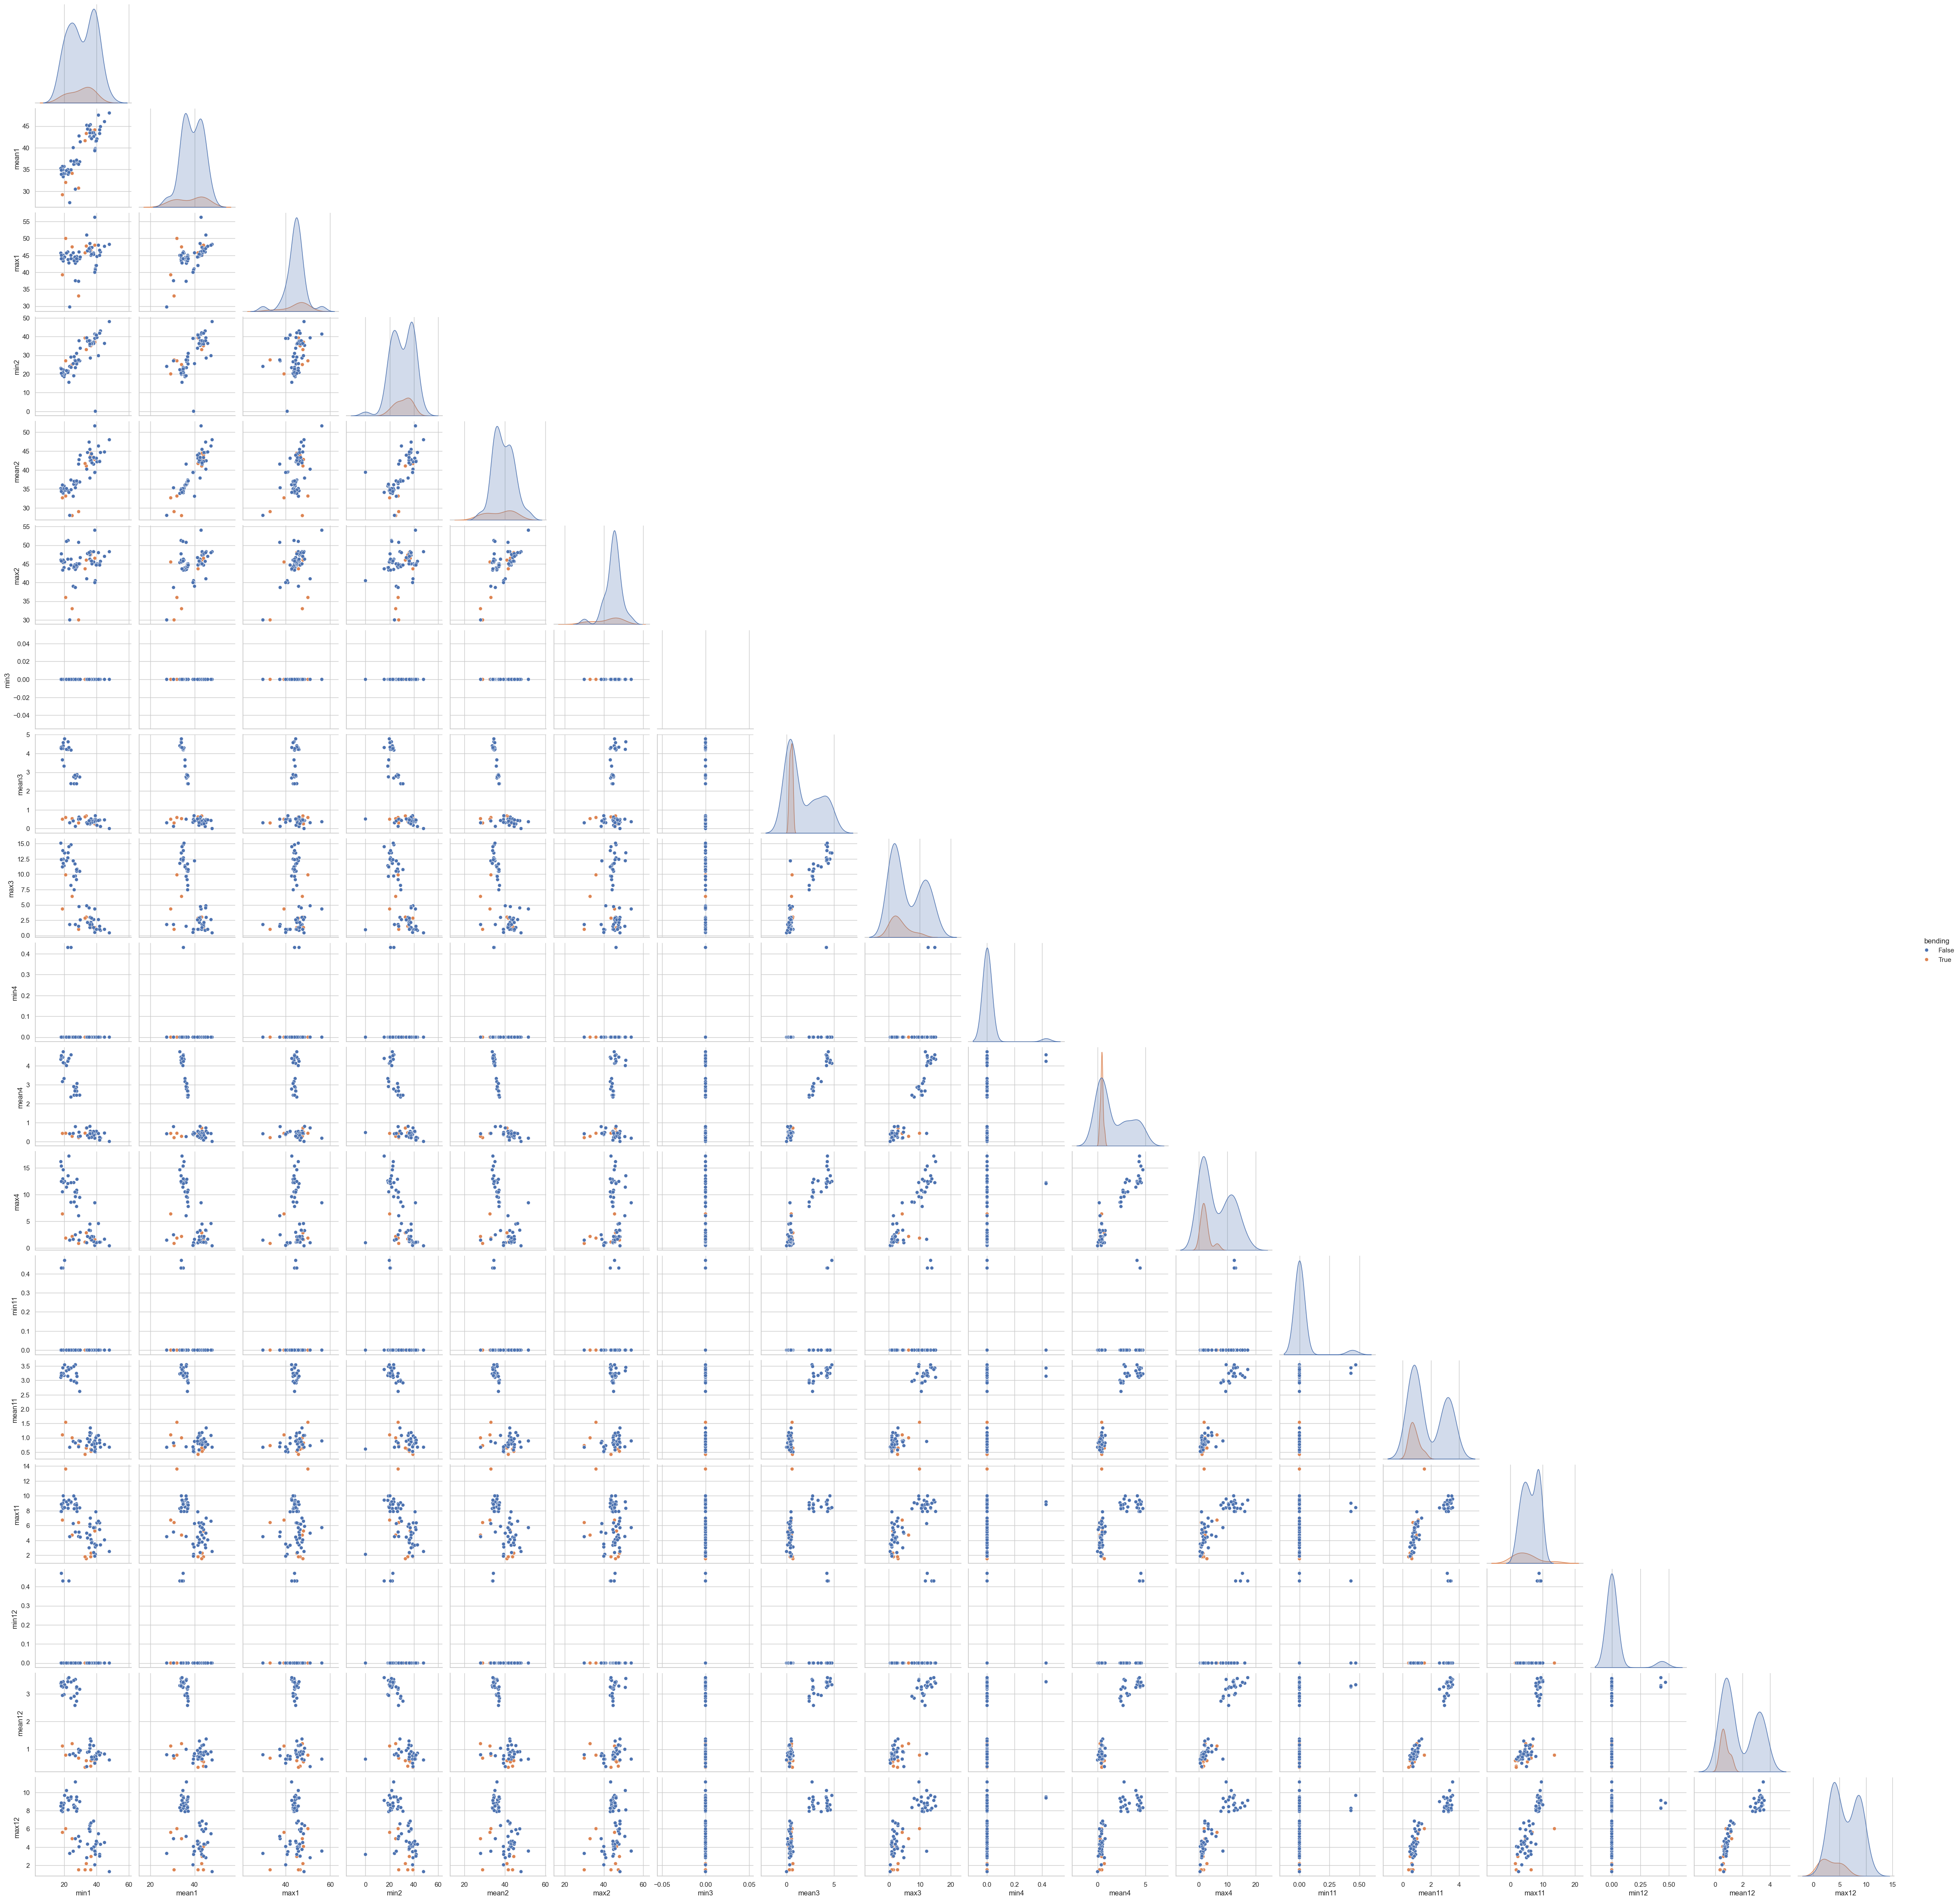

In [8]:
f2 = make_features(raw, 2)
train2 = f2[f2["split"] == "train"].copy()
train2["bending"] = train2["activity"].str.startswith("bending")

cols2 = [f"{stat}{k}" for k in [1, 2, 3, 4, 11, 12] for stat in ["min", "mean", "max"]]

sns.pairplot(train2, vars=cols2, hue="bending", corner=True)
plt.show()

There is no considerable difference from 2(a)i. The features of the first and second halves are strongly correlated with each other (e.g., `min1` vs. `min2`, which are now the two halves of series 1), so each half gives nearly the same picture as the full series: bending again sits within the low-variance cluster and overlaps with other non-moving activities.

### 2(a)iii Logistic regression with recursive feature elimination

For each *l* ∈ {1, …, 20} and each number of features *p* ∈ {1, …, 10}, a logistic regression with recursive feature elimination (RFE) is evaluated with 5-fold cross-validation. To keep the search tractable, the candidate features are min, mean, and max of each piece (3 × 6 × *l* features).

- **No regularization:** `penalty=None` removes scikit-learn's default L2 penalty.
- **Separable classes:** `max_iter=100` stops the solver early if the classes are linearly separable.
- **Class imbalance:** with only 9 bending instances, stratified folds keep the bending/other ratio the same in every fold so that no fold lacks the rare class.

**Right vs. wrong way to cross-validate.** The *wrong* way is to run feature selection (RFE, or p-value pruning) on all training data first and then cross-validate a model on the selected features. The held-out fold has then already influenced which features were chosen, so the CV accuracy is optimistically biased. The *right* way, used here, puts scaling and RFE inside a `Pipeline`, so that on every fold, features are selected using only that fold's training portion, and the held-out portion is used only for scoring. The value of *l* is likewise chosen by the CV score, never by the test set.

In [9]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

def get_Xy(l, which="train", stats=("min", "mean", "max")):
    f = make_features(raw, l)
    f = f[f["split"] == which]
    cols = [c for c in f.columns if c.rstrip("0123456789") in stats]
    X = f[cols]
    y = f["activity"].str.startswith("bending").astype(int)
    return X, y

X, y = get_Xy(1)
print(X.shape, y.sum())

(69, 18) 9


In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
results = []

for l in range(1, 21):
    X, y = get_Xy(l)
    for p in range(1, 11):
        model = Pipeline([
            ("scale", StandardScaler()),
            ("rfe", RFE(LogisticRegression(penalty=None, max_iter=100),
                        n_features_to_select=p, step=0.1)),
        ])
        acc = cross_val_score(model, X, y, cv=cv).mean()
        results.append((l, p, acc))
    print("done l =", l)

res = pd.DataFrame(results, columns=["l", "p", "cv_acc"])
res.sort_values(["cv_acc", "l", "p"], ascending=[False, True, True]).head(10)

done l = 1
done l = 2
done l = 3
done l = 4
done l = 5
done l = 6
done l = 7
done l = 8
done l = 9
done l = 10
done l = 11
done l = 12
done l = 13
done l = 14
done l = 15
done l = 16
done l = 17
done l = 18
done l = 19
done l = 20


,l,p,cv_acc
8,1,9,1.000000
9,1,10,1.000000
24,3,5,0.985714
27,3,8,0.985714
5,1,6,0.971429
6,1,7,0.971429
7,1,8,0.971429
16,2,7,0.971429
17,2,8,0.971429
18,2,9,0.971429


### 2(a)iv Final model on the training data

The best (*l*, *p*) pair is refit on all training data. Ties in CV accuracy are broken by choosing the smallest *l*, then the smallest *p*.

Best l = 1  p = 9  CV accuracy = 1.0
Selected features: ['min1', 'max2', 'min3', 'mean3', 'max4', 'mean4', 'min5', 'max5', 'mean5']
Confusion matrix (train):
 [[60  0]
 [ 0  9]]
Train AUC: 1.0


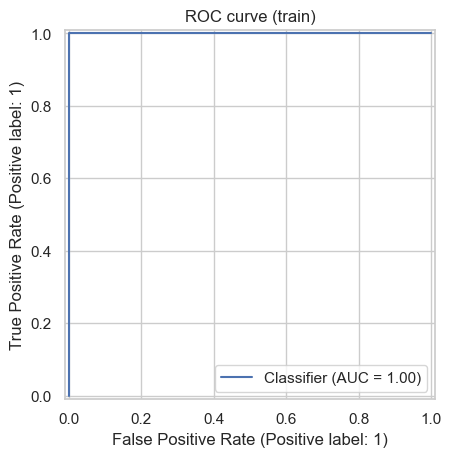

In [11]:
best = res.sort_values(["cv_acc", "l", "p"], ascending=[False, True, True]).iloc[0]
l_best, p_best = int(best["l"]), int(best["p"])
print("Best l =", l_best, " p =", p_best, " CV accuracy =", round(best["cv_acc"], 3))

X_tr, y_tr = get_Xy(l_best, "train")
final = Pipeline([
    ("scale", StandardScaler()),
    ("rfe", RFE(LogisticRegression(penalty=None, max_iter=100),
                n_features_to_select=p_best, step=0.1)),
])
final.fit(X_tr, y_tr)

selected = X_tr.columns[final.named_steps["rfe"].support_]
print("Selected features:", list(selected))

pred_tr = final.predict(X_tr)
prob_tr = final.predict_proba(X_tr)[:, 1]
print("Confusion matrix (train):\n", confusion_matrix(y_tr, pred_tr))
print("Train AUC:", roc_auc_score(y_tr, prob_tr))
RocCurveDisplay.from_predictions(y_tr, prob_tr)
plt.title("ROC curve (train)")
plt.show()

Coefficients β̂ᵢ and their p-values (statsmodels, on the standardized selected features):

In [12]:
Xs = pd.DataFrame(final.named_steps["scale"].transform(X_tr),
                  columns=X_tr.columns, index=X_tr.index)[selected]
logit = sm.Logit(y_tr, sm.add_constant(Xs)).fit(method="bfgs", maxiter=100, disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:               activity   No. Observations:                   69
Model:                          Logit   Df Residuals:                       59
Method:                           MLE   Df Model:                            9
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        12:58:44   Log-Likelihood:            -0.00023274
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 2.417e-08
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -34.8203      5e+05  -6.97e-05      1.000   -9.79e+05    9.79e+05
min1          -6.9564   1.34e+05  -5.18e-05      1.000   -2.63e+05    2.63e+05
max2          -4.3580   8.13e+04  -5.36e-05      1.0

### 2(a)v Test set

The test series are split into the same *l* pieces, and features are extracted from the test data.

In [13]:
X_te, y_te = get_Xy(l_best, "test")
pred_te = final.predict(X_te)
print("Confusion matrix (test):\n", confusion_matrix(y_te, pred_te))
print(f"Test accuracy: {accuracy_score(y_te, pred_te):.3f}   CV accuracy: {best['cv_acc']:.3f}")

Confusion matrix (test):
 [[15  0]
 [ 1  3]]
Test accuracy: 0.947   CV accuracy: 1.000


The cross-validation accuracy was 1.0. With only 19 test instances, each misclassification lowers test accuracy by about 5 percentage points, so the test accuracy above should be read as a rough check on the CV estimate rather than a precise measurement.

### 2(a)vi Separation and instability

Yes. The model reaches 100% cross-validation accuracy, a perfect training confusion matrix, and a training AUC of 1.0, so bending and the other activities are (linearly) perfectly separable in this feature space. Under perfect separation the maximum-likelihood estimates do not exist: the likelihood keeps increasing as the coefficients grow, so the β̂ᵢ diverge, their standard errors become very large, and the p-values above are not reliable. Capping the number of iterations stops the solver before the coefficients blow up.

### 2(a)vii Class imbalance and case-control sampling

The training confusion matrix shows 60 "other" vs. 9 "bending" instances, so the classes are imbalanced. A case-control model keeps all 9 cases and randomly samples 9 controls, then adjusts the intercept back to the true class proportion:

$$\hat\beta_0^* = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tau}{1-\tau},$$

where π = 9/69 is the true bending proportion and τ = 0.5 is the proportion in the case-control sample.

Case-control confusion matrix (train):
 [[59  1]
 [ 0  9]]
Case-control AUC: 1.0


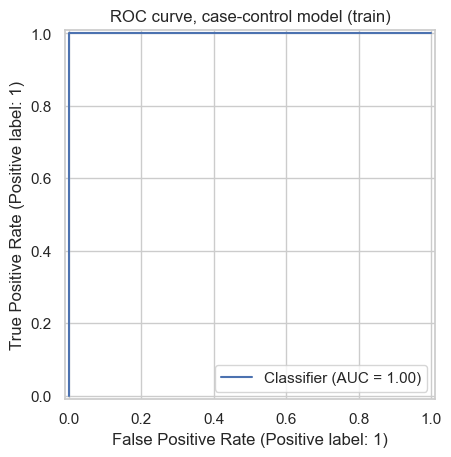

In [14]:
cases = X_tr[y_tr == 1]
controls = X_tr[y_tr == 0].sample(n=len(cases), random_state=0)
X_cc = pd.concat([cases, controls])
y_cc = y_tr.loc[X_cc.index]

cc = Pipeline([("scale", StandardScaler()),
               ("lr", LogisticRegression(penalty=None, max_iter=100))])
cc.fit(X_cc[selected], y_cc)

pi, tau = y_tr.mean(), y_cc.mean()
cc.named_steps["lr"].intercept_ += np.log(pi / (1 - pi)) - np.log(tau / (1 - tau))

prob_cc = cc.predict_proba(X_tr[selected])[:, 1]
pred_cc = (prob_cc >= 0.5).astype(int)
print("Case-control confusion matrix (train):\n", confusion_matrix(y_tr, pred_cc))
print("Case-control AUC:", roc_auc_score(y_tr, prob_cc))
RocCurveDisplay.from_predictions(y_tr, prob_cc)
plt.title("ROC curve, case-control model (train)")
plt.show()

The case-control model misclassifies one "other" instance as bending on the training data and keeps an AUC of 1.0. Because the classes are already well separated, rebalancing the sample changes the classifier very little.

### 2(b)i L1-penalized logistic regression

Instead of selecting features with p-values or RFE, an L1 penalty shrinks unhelpful coefficients to exactly zero. Both *l* and the budget *C* (smaller *C* means a stronger penalty) are chosen by stratified 5-fold cross-validation. Features are standardized inside the pipeline, and the liblinear solver is used.

In [15]:
Cs = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]
results_l1 = []

for l in range(1, 21):
    X, y = get_Xy(l)
    for C in Cs:
        model = Pipeline([
            ("scale", StandardScaler()),
            ("lr", LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=1000)),
        ])
        acc = cross_val_score(model, X, y, cv=cv).mean()
        results_l1.append((l, C, acc))

res_l1 = pd.DataFrame(results_l1, columns=["l", "C", "cv_acc"])
best_l1 = res_l1.sort_values(["cv_acc", "l", "C"], ascending=[False, True, True]).iloc[0]
l1_l, l1_C = int(best_l1["l"]), best_l1["C"]
print("Best l =", l1_l, " C =", l1_C, " CV accuracy =", round(best_l1["cv_acc"], 3))

Best l = 1  C = 100.0  CV accuracy = 1.0


In [16]:
X_tr1, y_tr1 = get_Xy(l1_l, "train")
X_te1, y_te1 = get_Xy(l1_l, "test")

l1_model = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(penalty="l1", C=l1_C, solver="liblinear", max_iter=1000)),
])
l1_model.fit(X_tr1, y_tr1)

coefs = pd.Series(l1_model.named_steps["lr"].coef_[0], index=X_tr1.columns)
print("Nonzero coefficients:\n", coefs[coefs != 0])

pred_te1 = l1_model.predict(X_te1)
print("Confusion matrix (test):\n", confusion_matrix(y_te1, pred_te1))
print("Test accuracy:", accuracy_score(y_te1, pred_te1))

Nonzero coefficients:
 min1    -0.710725
mean1   -1.363981
max2    -1.424114
min3    -0.149405
mean3   -2.545443
max4     0.003664
min5     5.336043
max5     6.812009
mean5    0.292478
mean6   -0.587176
dtype: float64
Confusion matrix (test):
 [[15  0]
 [ 1  3]]
Test accuracy: 0.9473684210526315


### 2(b)ii Comparison with p-value / RFE variable selection

Both approaches reach 100% cross-validation accuracy with *l* = 1. The L1 model keeps 10 of the 18 features and reaches a test accuracy of 0.947 (one bending instance missed); compare with the RFE model's test accuracy in 2(a)v. With such a small test set, the two perform essentially the same. L1 regularization is easier to implement: a single model selects features and fits coefficients at the same time with one tuning parameter, while the p-value / RFE approach needs a separate elimination loop over *p*, refitting, and a second library to obtain p-values. L1 is also better behaved when the classes are separable, because the penalty keeps the coefficients finite.

### 2(c) Multiclass classification

**Multiclass evaluation.** For *K* classes, the confusion matrix is *K* × *K*: rows are true classes and columns are predicted classes, so the diagonal counts correct predictions. ROC curves are defined one-vs-rest: for each class, that class is treated as positive and all others as negative, giving one ROC curve and AUC per class.

In [17]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import label_binarize

def get_Xy_multi(l, which="train", stats=("min", "mean", "max")):
    f = make_features(raw, l)
    f = f[f["split"] == which]
    cols = [c for c in f.columns if c.rstrip("0123456789") in stats]
    return f[cols], f["activity"]

def evaluate(model, l, name):
    X_tr, y_tr = get_Xy_multi(l, "train")
    X_te, y_te = get_Xy_multi(l, "test")
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    print(f"{name}: l = {l}, test error = {1 - accuracy_score(y_te, pred):.3f}")
    labels = model.classes_
    print(pd.DataFrame(confusion_matrix(y_te, pred, labels=labels),
                       index=labels, columns=labels))
    prob = model.predict_proba(X_te)
    Y = label_binarize(y_te, classes=labels)
    fig, ax = plt.subplots(figsize=(6, 5))
    for i, c in enumerate(labels):
        RocCurveDisplay.from_predictions(Y[:, i], prob[:, i], name=c, ax=ax)
    ax.set_title(f"One-vs-rest ROC (test): {name}")
    plt.show()

cvm = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

#### 2(c)i L1-penalized multinomial regression

In [ ]:
Cs_m = [0.1, 1, 10, 100]
rows = []
for l in range(1, 21):
    X, y = get_Xy_multi(l)
    for C in Cs_m:
        m = Pipeline([("scale", StandardScaler()),
                      ("lr", LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=2000))])
        rows.append((l, C, cross_val_score(m, X, y, cv=cvm).mean()))
    print("done l =", l)

res_m = pd.DataFrame(rows, columns=["l", "C", "cv_acc"])
bm = res_m.sort_values(["cv_acc", "l", "C"], ascending=[False, True, True]).iloc[0]
print("Best:", bm.to_dict())

evaluate(Pipeline([("scale", StandardScaler()),
                   ("lr", LogisticRegression(penalty="l1", C=bm["C"], solver="saga", max_iter=2000))]),
         int(bm["l"]), "L1 multinomial")

done l = 1
done l = 2
done l = 3
done l = 4
done l = 5
done l = 6
done l = 7
done l = 8
done l = 9
done l = 10
done l = 11


#### 2(c)ii Naive Bayes (Gaussian and Multinomial)

In [ ]:
for name, make in [("Gaussian NB", GaussianNB), ("Multinomial NB", MultinomialNB)]:
    scores = [(l, cross_val_score(make(), *get_Xy_multi(l), cv=cvm).mean()) for l in range(1, 21)]
    best_l = max(scores, key=lambda t: (t[1], -t[0]))[0]
    print(name, "best l =", best_l, " CV accuracy =", round(dict(scores)[best_l], 3))
    evaluate(make(), best_l, name)

#### 2(c)iii Which method is better?

| Model | Best *l* | CV accuracy | Test error |
|---|---|---|---|
| L1 multinomial regression | 1 | 0.884 | 0.053 |
| Gaussian Naive Bayes | 2 | 0.857 | 0.053 |
| Multinomial Naive Bayes | 5 | 0.825 | 0.263 |

L1-penalized multinomial regression is the best choice: it ties Gaussian Naive Bayes for the lowest test error (18 of 19 correct; both confuse one standing instance) and has the highest cross-validation accuracy, which is the more reliable comparison given the tiny test set. Gaussian NB is a close second. Multinomial NB performs worst because it models count data, while these features are continuous; it confuses sitting with standing and misclassifies both bending2 test instances.

## 3. ISLR 4.8.3

With one predictor and class-specific variances, $f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)$. The Bayes classifier assigns $x$ to the class maximizing $\pi_k f_k(x)$, or equivalently (since log is increasing) its logarithm. Dropping the term $-\log\sqrt{2\pi}$, which is the same for every class:

$$\delta_k(x) = -\frac{(x-\mu_k)^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k x}{\sigma_k^2} - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k.$$

In LDA all $\sigma_k$ are equal, so the $x^2$ term is the same for every class and cancels when classes are compared, leaving a linear discriminant. Here $\sigma_k$ differs across classes, so the coefficient $-1/(2\sigma_k^2)$ of $x^2$ differs and does not cancel. Therefore $\delta_k(x)$ is a quadratic function of $x$, and the Bayes classifier is quadratic, not linear.

## 4. ISLR 4.8.7

With $\bar X = 10$ for companies that issued a dividend, $\bar X = 0$ for those that did not, common variance $\sigma^2 = 36$, and prior $\pi_{\text{yes}} = 0.8$ (the normalizing constants cancel because the variance is shared):

$$P(Y=\text{yes}\mid X=4) = \frac{0.8\,e^{-(4-10)^2/72}}{0.8\,e^{-(4-10)^2/72} + 0.2\,e^{-(4-0)^2/72}} = \frac{0.8\,e^{-0.5}}{0.8\,e^{-0.5} + 0.2\,e^{-0.222}} \approx 0.752.$$

In [ ]:
num = 0.8 * np.exp(-(4 - 10)**2 / 72)
den = num + 0.2 * np.exp(-(4 - 0)**2 / 72)
print(num / den)